## LaDe 17: Contextual Delivery Prioritization (Flag 17)

### Dataset Overview

Constructed LaDe-style Shanghai case: 59 tasks, 1 courier(s), 1 courier-workday trajectories and 5488 GPS points. Routes follow the archived local OSM street network with oneway directions respected; restricted-access ways and expressways are excluded. Turn-restriction relations are not modeled. AOIs are constructed road-centered catchments, not official polygons. All times are local Shanghai time. Each task is accepted before selection and completion; the full candidate table records every pending task at each decision. speed_kmh is the mean speed of the immediately preceding GPS segment (zero during waiting/service), not an instantaneous endpoint speed. Empty last_near_destination_before_acceptance means no prior GPS observation within 250 m. Deadline-expired observations remain valid and represent late tasks; this is not an all-on-time dataset.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Analyze how the courier prioritizes delivery tasks during the workday.

Role: Last-mile courier operations analyst


Category: contextual_delivery_prioritization


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "delivery_tasks.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: When workload is high, does the courier prioritize closer destinations or earlier-accepted tasks?

#### Analysis action

Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.

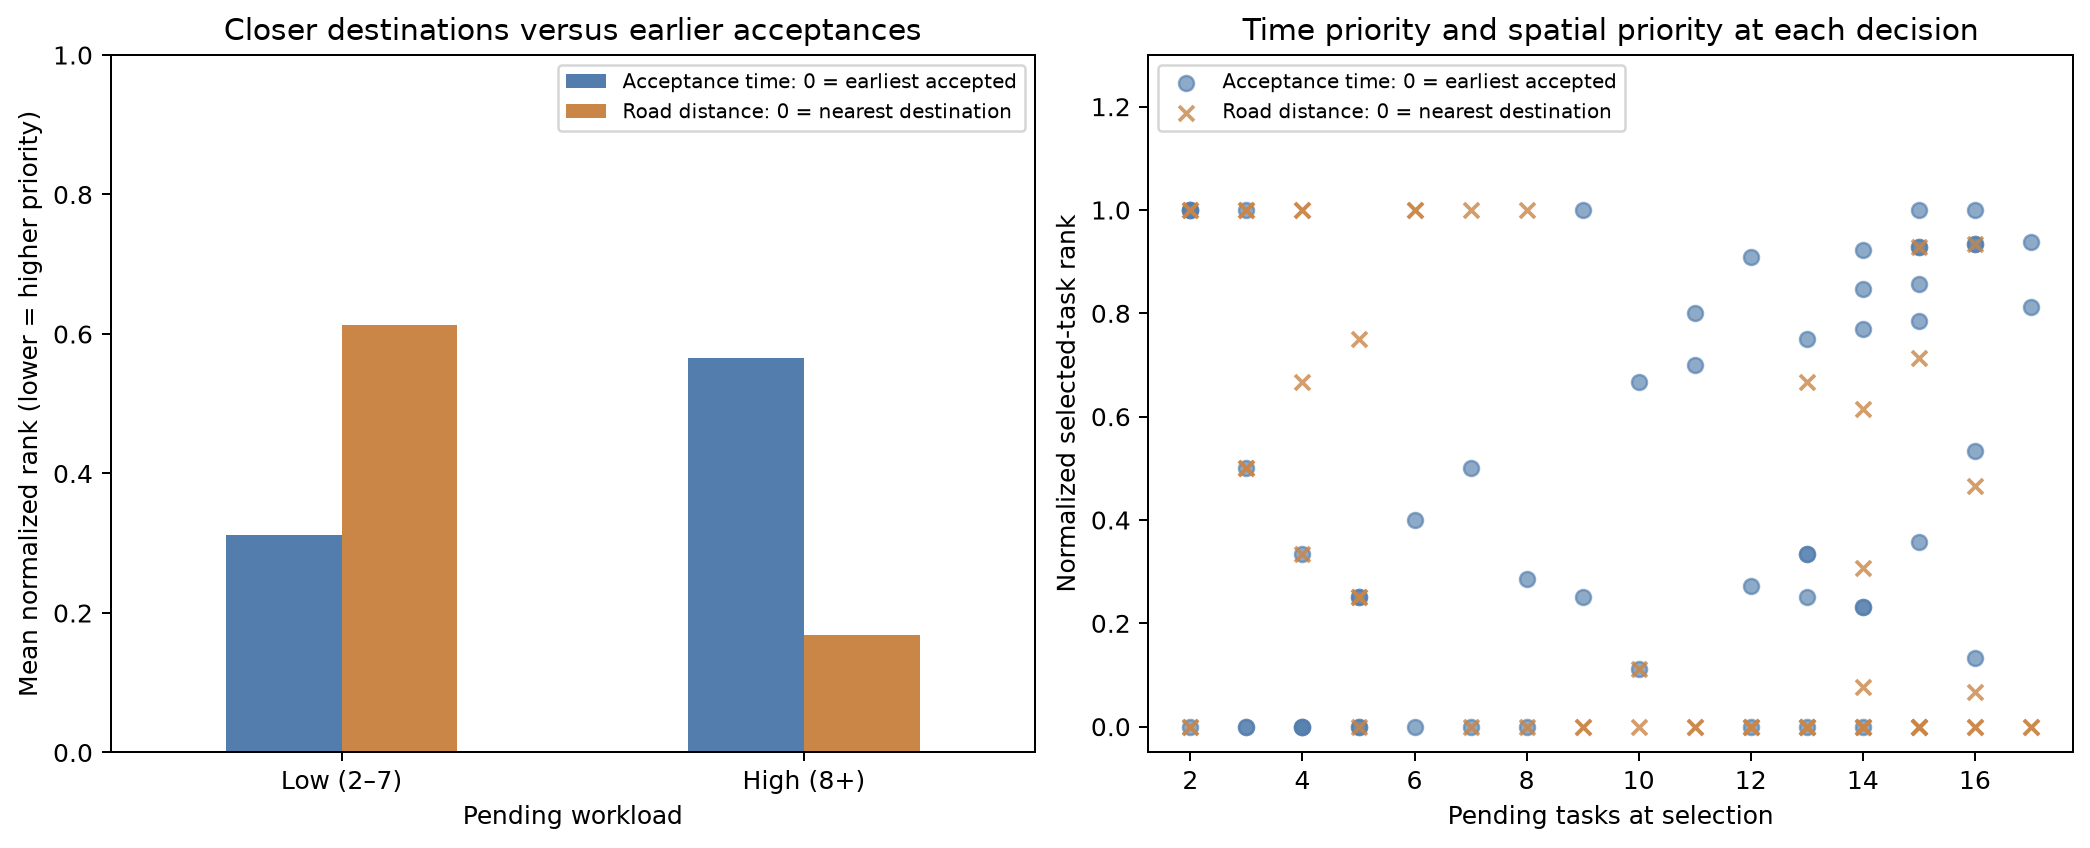

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

decisions = pd.read_csv("decision_candidates.csv")


def backlog_priority(df, user_df, decisions):
    d = decisions[decisions.selected & decisions.pending_count.ge(2)].copy()
    d["acceptance_rank_fraction"] = (d.acceptance_rank - 1) / (d.pending_count - 1)
    d["proximity_rank_fraction"] = (d.proximity_rank - 1) / (d.pending_count - 1)
    d["backlog"] = np.where(d.pending_count >= 8, "High (8+)", "Low (2–7)")
    means = d.groupby("backlog")[
        ["acceptance_rank_fraction", "proximity_rank_fraction"]
    ].mean()
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), constrained_layout=True)
    means.reindex(["Low (2–7)", "High (8+)"]).plot.bar(
        ax=axes[0], color=["#527dac", "#ca8647"], rot=0
    )
    axes[0].set(
        xlabel="Pending workload",
        ylabel="Mean normalized rank (lower = higher priority)",
        title="Closer destinations versus earlier acceptances",
        ylim=(0, 1),
    )
    axes[0].legend(
        [
            "Acceptance time: 0 = earliest accepted",
            "Road distance: 0 = nearest destination",
        ],
        fontsize=8,
    )
    axes[1].scatter(
        d.pending_count,
        d.acceptance_rank_fraction,
        c="#527dac",
        alpha=0.65,
        label="Acceptance time: 0 = earliest accepted",
    )
    axes[1].scatter(
        d.pending_count,
        d.proximity_rank_fraction,
        c="#ca8647",
        marker="x",
        alpha=0.8,
        label="Road distance: 0 = nearest destination",
    )
    axes[1].set(
        xlabel="Pending tasks at selection",
        ylabel="Normalized selected-task rank",
        title="Time priority and spatial priority at each decision",
        ylim=(-0.05, 1.3),
    )
    axes[1].legend(fontsize=8, loc="upper left")
    return {"selected_decisions": len(d), "mean_normalized_ranks": means.to_dict()}


evidence = backlog_priority(df, user_df, decisions)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (8 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "backlog_priority",
  "insight": "When more tasks are pending, the courier tends to prioritize tasks with closer destinations over tasks accepted earlier.",
  "insight_type": "factor_relationship",
  "insight_value": {
    "selected_decisions": 55,
    "mean_normalized_ranks": {
      "acceptance_rank_fraction": {
        "High (8+)": 0.565784374355803,
        "Low (2–7)": 0.31166666666666665
      },
      "proximity_rank_fraction": {
        "High (8+)": 0.16820861678004537,
        "Low (2–7)": 0.6125
      }
    }
  },
  "question": "When workload is high, does the courier prioritize closer destinations or earlier-accepted tasks?",
  "actionable_insight": "Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "When workload is high, does the courier prioritize closer destinations or earlier-accepted tasks?",
    "file": "visualizations/insight_1.png",
    "description": "Blue measures acceptance-time priority (0 = earliest accepted); orange measures road-distance priority (0 = nearest destination). Both ranks are normalized within the pending queue."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\ndecisions = pd.read_csv(\"decision_candidates.csv\")\n\ndef backlog_priority(df,user_df,decisions):\n    d=decisions[decisions.selected & decisions.pending_count.ge(2)].copy()\n    d['acceptance_rank_fraction']=(d.acceptance_rank-1)/(d.pending_count-1)\n    d['proximity_rank_fraction']=(d.proximity_rank-1)/(d.pending_count-1)\n    d['backlog']=np.where(d.pending_count>=8,'High (8+)','Low (2–7)')\n    means=d.groupby('backlog')[['acceptance_rank_fraction','proximity_rank_fraction']].mean()\n    fig,axes=plt.subplots(1,2,figsize=(11.5,4.6),constrained_layout=True)\n    means.reindex(['Low (2–7)','High (8+)']).plot.bar(ax=axes[0],color=['#527dac','#ca8647'],rot=0)\n    axes[0].set(xlabel='Pending workload',ylabel='Mean normalized rank (lower = higher priority)',title='Closer destinations versus earlier acceptances',ylim=(0,1))\n    axes[0].legend(['Acceptance time: 0 = earliest accepted','Road distance: 0 = nearest destination'],fontsize=8)\n    axes[1].scatter(d.pending_count,d.acceptance_rank_fraction,c='#527dac',alpha=.65,label='Acceptance time: 0 = earliest accepted')\n    axes[1].scatter(d.pending_count,d.proximity_rank_fraction,c='#ca8647',marker='x',alpha=.8,label='Road distance: 0 = nearest destination')\n    axes[1].set(xlabel='Pending tasks at selection',ylabel='Normalized selected-task rank',title='Time priority and spatial priority at each decision',ylim=(-.05,1.3))\n    axes[1].legend(fontsize=8,loc='upper left')\n    return {'selected_decisions':len(d),'mean_normalized_ranks':means.to_dict()}\n\nevidence = backlog_priority(df, user_df, decisions)\nprint(evidence)\nplt.show()",
  "difficulty_level": 8,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "completion_time",
    "task_position",
    "gps_time",
    "gps_position",
    "task_id",
    "courier_id",
    "road_network_reference"
  ]
}

### **Question 2**: When an urgent task competes with a closer loose-window task, which is completed first?

#### Analysis action

Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.

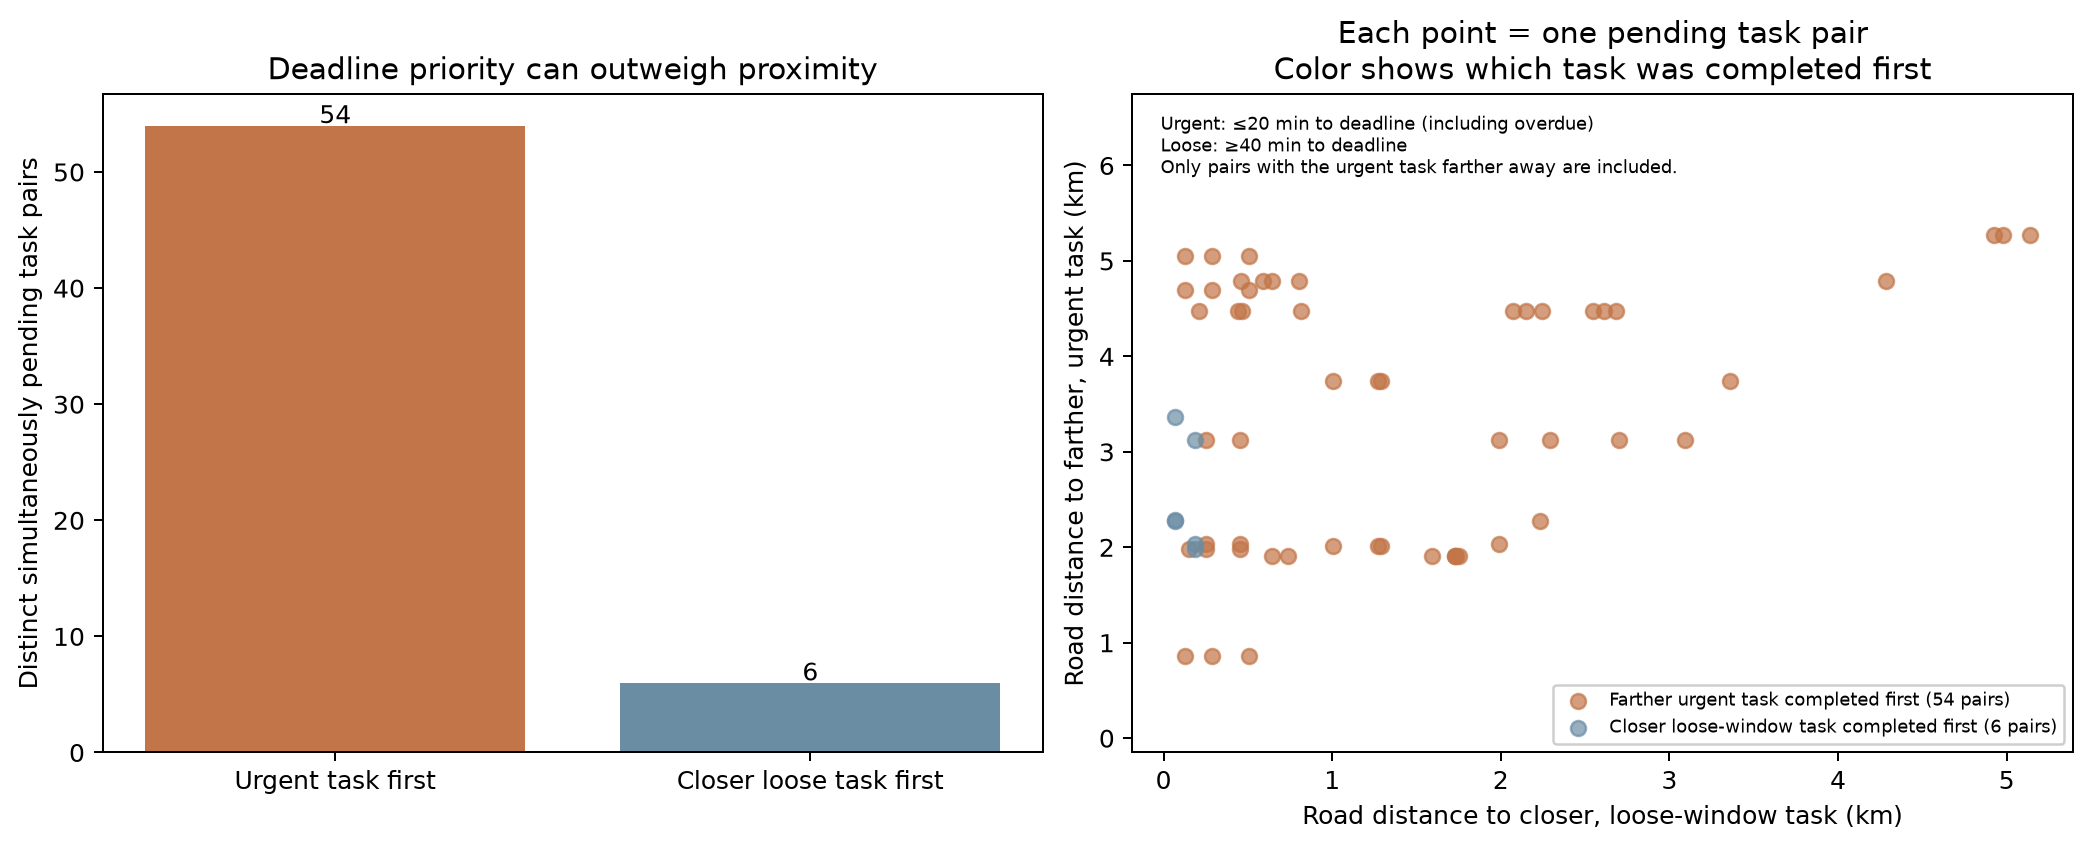

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

decisions = pd.read_csv("decision_candidates.csv")


def deadline_priority(df, user_df, decisions):
    pairs = {}
    order = df.set_index("task_id").completion_order
    for _, q in decisions.groupby("decision_id", sort=False):
        for _, urgent in q[q.remaining_window_min.le(20)].iterrows():
            for _, loose in q[
                (q.remaining_window_min >= 40)
                & (q.candidate_distance_km < urgent.candidate_distance_km)
            ].iterrows():
                key = (urgent.candidate_task_id, loose.candidate_task_id)
                pairs.setdefault(
                    key,
                    {
                        "urgent": key[0],
                        "loose": key[1],
                        "urgent_distance": urgent.candidate_distance_km,
                        "loose_distance": loose.candidate_distance_km,
                        "urgent_remaining": urgent.remaining_window_min,
                        "loose_remaining": loose.remaining_window_min,
                        "urgent_first": bool(order[key[0]] < order[key[1]]),
                    },
                )
    pairs = pd.DataFrame(pairs.values())
    assert len(pairs)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), constrained_layout=True)
    rates = pairs.urgent_first.value_counts().reindex([True, False], fill_value=0)
    axes[0].bar(
        ["Urgent task first", "Closer loose task first"],
        rates,
        color=["#c27548", "#6b8da4"],
    )
    axes[0].set(
        ylabel="Distinct simultaneously pending task pairs",
        title="Deadline priority can outweigh proximity",
    )
    for i, v in enumerate(rates):
        axes[0].text(i, v + 0.2, str(v), ha="center")
    for first, color, label in [
        (True, "#c27548", "Farther urgent task completed first"),
        (False, "#6b8da4", "Closer loose-window task completed first"),
    ]:
        subset = pairs[pairs.urgent_first == first]
        axes[1].scatter(
            subset.loose_distance,
            subset.urgent_distance,
            color=color,
            alpha=0.7,
            label=f"{label} ({len(subset)} pairs)",
        )
    lim = max(pairs.urgent_distance.max(), pairs.loose_distance.max()) * 1.05
    axes[1].set(
        xlabel="Road distance to closer, loose-window task (km)",
        ylabel="Road distance to farther, urgent task (km)",
        title=(
            "Each point = one pending task pair\nColor shows which task was completed"
            " first"
        ),
    )
    axes[1].legend(loc="lower right", fontsize=7, framealpha=0.95)
    axes[1].text(
        0.03,
        0.97,
        "Urgent: ≤20 min to deadline (including overdue)\nLoose: ≥40 min to"
        " deadline\nOnly pairs with the urgent task farther away are included.",
        transform=axes[1].transAxes,
        ha="left",
        va="top",
        fontsize=7,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
    )
    axes[1].set_ylim(-0.15, lim * 1.22)
    return {
        "urgent_threshold_min": 20,
        "loose_threshold_min": 40,
        "distinct_pairs": len(pairs),
        "distinct_urgent_tasks": int(pairs.urgent.nunique()),
        "urgent_completed_first_share": float(pairs.urgent_first.mean()),
    }


evidence = deadline_priority(df, user_df, decisions)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (9 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "deadline_priority",
  "insight": "Tasks approaching the end of their promised windows are often completed before nearby tasks with looser time constraints.",
  "insight_type": "factor_relationship",
  "insight_value": {
    "urgent_threshold_min": 20,
    "loose_threshold_min": 40,
    "distinct_pairs": 60,
    "distinct_urgent_tasks": 10,
    "urgent_completed_first_share": 0.9
  },
  "question": "When an urgent task competes with a closer loose-window task, which is completed first?",
  "actionable_insight": "Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "When an urgent task competes with a closer loose-window task, which is completed first?",
    "file": "visualizations/insight_2.png",
    "description": "Each point is a distinct simultaneously pending task pair, using its first qualifying snapshot. The urgent task has at most 20 minutes remaining (including overdue), the closer loose-window task at least 40 minutes. Orange means the farther urgent task completed first; blue means the closer loose-window task completed first. The urgent task is farther away by selection; no reference or fitted line is shown."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\ndecisions = pd.read_csv(\"decision_candidates.csv\")\n\ndef deadline_priority(df,user_df,decisions):\n    pairs={}\n    order=df.set_index('task_id').completion_order\n    for _,q in decisions.groupby('decision_id',sort=False):\n        for _,urgent in q[q.remaining_window_min.le(20)].iterrows():\n            for _,loose in q[(q.remaining_window_min>=40)&(q.candidate_distance_km<urgent.candidate_distance_km)].iterrows():\n                key=(urgent.candidate_task_id,loose.candidate_task_id)\n                pairs.setdefault(key,{'urgent':key[0],'loose':key[1],\n                    'urgent_distance':urgent.candidate_distance_km,'loose_distance':loose.candidate_distance_km,\n                    'urgent_remaining':urgent.remaining_window_min,'loose_remaining':loose.remaining_window_min,\n                    'urgent_first':bool(order[key[0]]<order[key[1]])})\n    pairs=pd.DataFrame(pairs.values());assert len(pairs)\n    fig,axes=plt.subplots(1,2,figsize=(11.5,4.6),constrained_layout=True)\n    rates=pairs.urgent_first.value_counts().reindex([True,False],fill_value=0)\n    axes[0].bar(['Urgent task first','Closer loose task first'],rates,color=['#c27548','#6b8da4'])\n    axes[0].set(ylabel='Distinct simultaneously pending task pairs',title='Deadline priority can outweigh proximity')\n    for i,v in enumerate(rates):axes[0].text(i,v+.2,str(v),ha='center')\n    for first,color,label in [(True,'#c27548','Farther urgent task completed first'),\n                              (False,'#6b8da4','Closer loose-window task completed first')]:\n        subset=pairs[pairs.urgent_first==first]\n        axes[1].scatter(subset.loose_distance,subset.urgent_distance,color=color,alpha=.7,\n            label=f'{label} ({len(subset)} pairs)')\n    lim=max(pairs.urgent_distance.max(),pairs.loose_distance.max())*1.05\n    axes[1].set(xlabel='Road distance to closer, loose-window task (km)',\n        ylabel='Road distance to farther, urgent task (km)',\n        title='Each point = one pending task pair\\nColor shows which task was completed first')\n    axes[1].legend(loc='lower right',fontsize=7,framealpha=.95)\n    axes[1].text(.03,.97,'Urgent: ≤20 min to deadline (including overdue)\\nLoose: ≥40 min to deadline\\nOnly pairs with the urgent task farther away are included.',\n        transform=axes[1].transAxes,ha='left',va='top',fontsize=7,\n        bbox={'facecolor':'white','edgecolor':'none','alpha':.9})\n    axes[1].set_ylim(-.15,lim*1.22)\n    return {'urgent_threshold_min':20,'loose_threshold_min':40,'distinct_pairs':len(pairs),\n            'distinct_urgent_tasks':int(pairs.urgent.nunique()),'urgent_completed_first_share':float(pairs.urgent_first.mean())}\n\nevidence = deadline_priority(df, user_df, decisions)\nprint(evidence)\nplt.show()",
  "difficulty_level": 9,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "completion_time",
    "time_window_end",
    "task_position",
    "gps_time",
    "gps_position",
    "task_id",
    "courier_id",
    "road_network_reference"
  ]
}

### **Question 3**: How does acceptance-to-completion delay differ between locally accepted tasks and tasks accepted after the courier moved away?

#### Analysis action

Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.

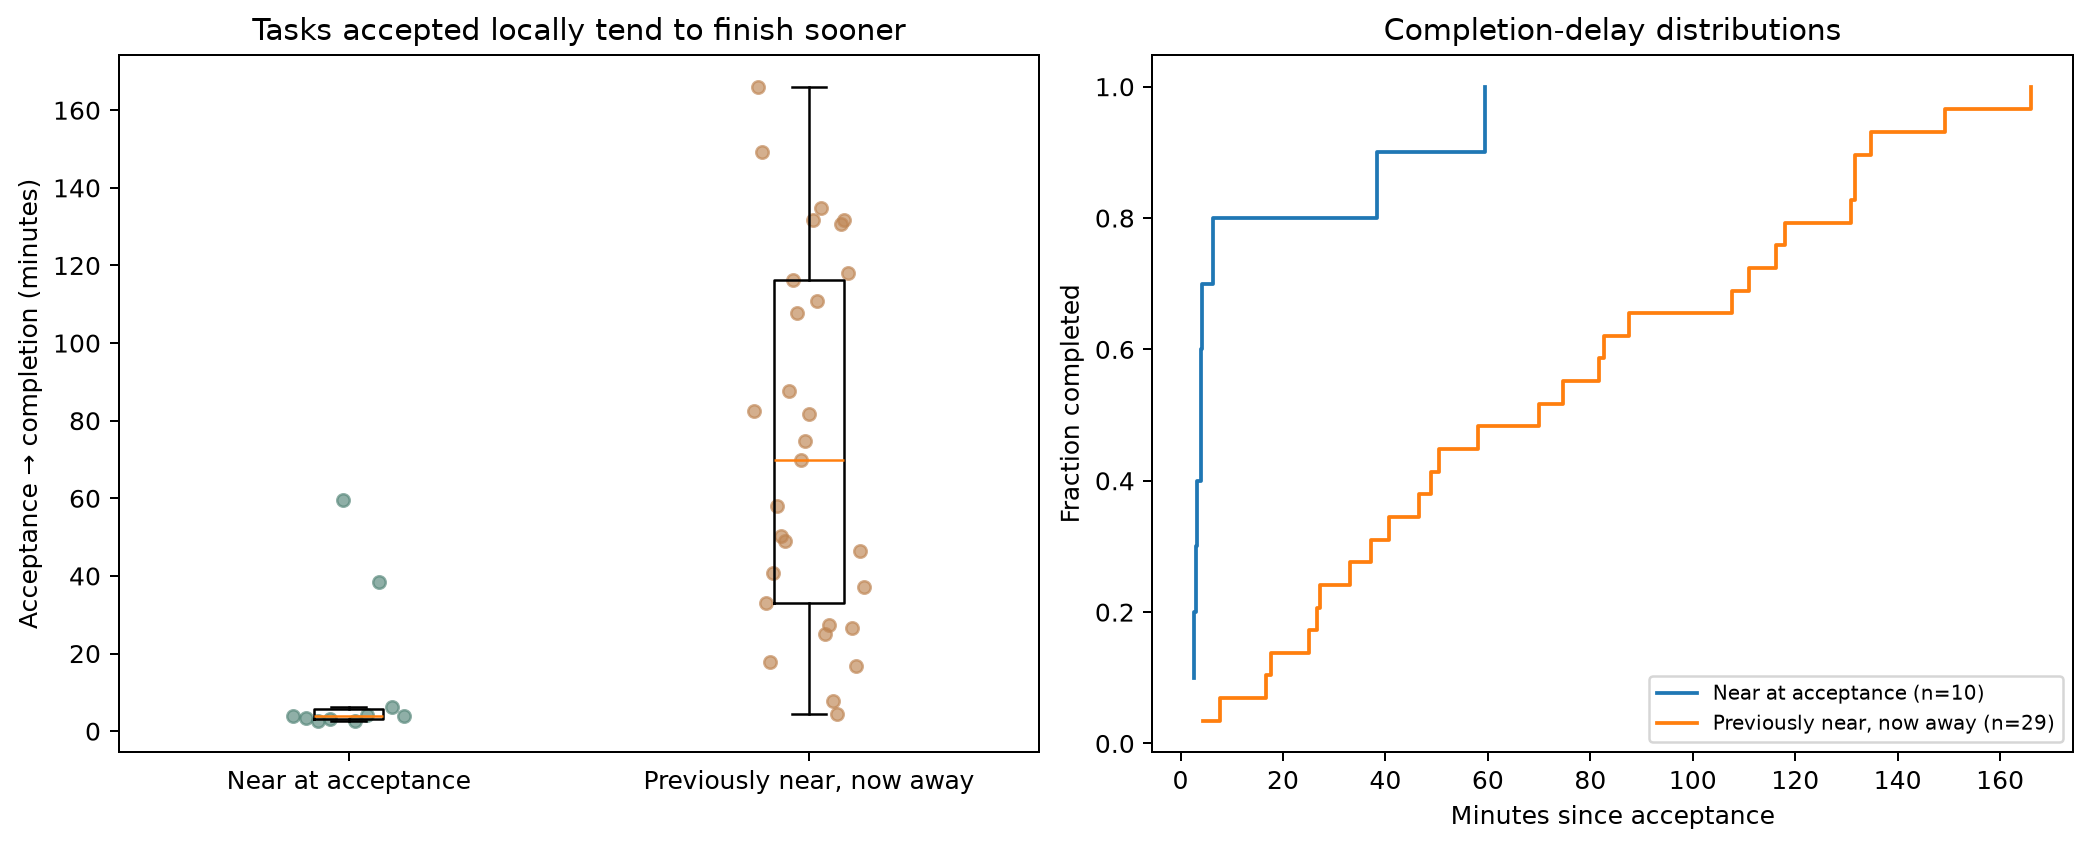

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

decisions = pd.read_csv("decision_candidates.csv")


def acceptance_location(df, user_df, decisions):
    near = df[df.acceptance_distance_km <= 0.25].copy()
    away = df[
        (df.acceptance_distance_km >= 0.8)
        & df.last_near_destination_before_acceptance.notna()
    ].copy()
    cohorts = [near, away]
    labels = ["Near at acceptance", "Previously near, now away"]
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), constrained_layout=True)
    axes[0].boxplot(
        [q.accept_to_completion_min for q in cohorts],
        tick_labels=labels,
        showfliers=False,
    )
    for i, q in enumerate(cohorts, 1):
        jitter = np.linspace(-0.12, 0.12, len(q))
        axes[0].scatter(
            i + jitter,
            q.accept_to_completion_min,
            s=25,
            alpha=0.65,
            color=["#548578", "#be8452"][i - 1],
        )
        ordered = np.sort(q.accept_to_completion_min)
        axes[1].step(
            ordered,
            np.arange(1, len(q) + 1) / len(q),
            where="post",
            label=f"{labels[i-1]} (n={len(q)})",
        )
    axes[0].set(
        ylabel="Acceptance → completion (minutes)",
        title="Tasks accepted locally tend to finish sooner",
    )
    axes[1].set(
        xlabel="Minutes since acceptance",
        ylabel="Fraction completed",
        title="Completion-delay distributions",
    )
    axes[1].legend(fontsize=8)
    return {
        "near_threshold_km": 0.25,
        "away_threshold_km": 0.8,
        "near_tasks": len(near),
        "previously_near_away_tasks": len(away),
        "median_minutes_near": float(near.accept_to_completion_min.median()),
        "median_minutes_away": float(away.accept_to_completion_min.median()),
        "near_faster_pairwise_share": float(
            (
                near.accept_to_completion_min.to_numpy()[:, None]
                < away.accept_to_completion_min.to_numpy()
            ).mean()
        ),
    }


evidence = acceptance_location(df, user_df, decisions)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "acceptance_location",
  "insight": "Tasks accepted while the courier is already near their destination area are usually completed sooner than those accepted after the courier has moved away.",
  "insight_type": "temporal_dynamics",
  "insight_value": {
    "near_threshold_km": 0.25,
    "away_threshold_km": 0.8,
    "near_tasks": 10,
    "previously_near_away_tasks": 29,
    "median_minutes_near": 3.9428542333333336,
    "median_minutes_away": 69.90914938333334,
    "near_faster_pairwise_share": 0.9172413793103448
  },
  "question": "How does acceptance-to-completion delay differ between locally accepted tasks and tasks accepted after the courier moved away?",
  "actionable_insight": "Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "How does acceptance-to-completion delay differ between locally accepted tasks and tasks accepted after the courier moved away?",
    "file": "visualizations/insight_3.png",
    "description": "All panels and displayed statistics are computed from the emitted CSV files."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nfrom scipy.stats import kendalltau\ndecisions = pd.read_csv(\"decision_candidates.csv\")\n\ndef acceptance_location(df,user_df,decisions):\n    near=df[df.acceptance_distance_km<=.25].copy()\n    away=df[(df.acceptance_distance_km>=.8)&df.last_near_destination_before_acceptance.notna()].copy()\n    cohorts=[near,away];labels=['Near at acceptance','Previously near, now away']\n    fig,axes=plt.subplots(1,2,figsize=(11.5,4.6),constrained_layout=True)\n    axes[0].boxplot([q.accept_to_completion_min for q in cohorts],tick_labels=labels,showfliers=False)\n    for i,q in enumerate(cohorts,1):\n        jitter=np.linspace(-.12,.12,len(q))\n        axes[0].scatter(i+jitter,q.accept_to_completion_min,s=25,alpha=.65,color=['#548578','#be8452'][i-1])\n        ordered=np.sort(q.accept_to_completion_min)\n        axes[1].step(ordered,np.arange(1,len(q)+1)/len(q),where='post',label=f'{labels[i-1]} (n={len(q)})')\n    axes[0].set(ylabel='Acceptance → completion (minutes)',title='Tasks accepted locally tend to finish sooner')\n    axes[1].set(xlabel='Minutes since acceptance',ylabel='Fraction completed',title='Completion-delay distributions');axes[1].legend(fontsize=8)\n    return {'near_threshold_km':.25,'away_threshold_km':.8,'near_tasks':len(near),'previously_near_away_tasks':len(away),\n            'median_minutes_near':float(near.accept_to_completion_min.median()),\n            'median_minutes_away':float(away.accept_to_completion_min.median()),\n            'near_faster_pairwise_share':float((near.accept_to_completion_min.to_numpy()[:,None]<away.accept_to_completion_min.to_numpy()).mean())}\n\nevidence = acceptance_location(df, user_df, decisions)\nprint(evidence)\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "completion_time",
    "task_position",
    "gps_time",
    "gps_position",
    "task_id"
  ]
}

### Summary of Findings (Flag 17)

When more tasks are pending, the courier tends to prioritize tasks with closer destinations over tasks accepted earlier. Tasks approaching the end of their promised windows are often completed before nearby tasks with looser time constraints. Tasks accepted while the courier is already near their destination area are usually completed sooner than those accepted after the courier has moved away.